# Notebook 04 — Multimodal Gated Fusion (GMU)
**Goal:** Combine image features and sensor features using a Gated Multimodal Unit (GMU)
for litchi freshness and formalin adulteration detection.

This is the **main model** of the project.

In [1]:
import os, warnings, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

warnings.filterwarnings('ignore')

TARGET_NAMES = ['Fresh', 'Formalin-Mixed', 'Rotten']
SENSOR_COLS = ['Moisture', 'Firmness', 'pH', 'TSS', 'Ethanol', 'CO2', 'Formaldehyde']
RESULTS_DIR = '../results'
MODELS_DIR = '../models'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Hyperparameters (optimized for CPU efficiency)
IMG_SIZE = 224
BATCH_SIZE = 64
EMBED_DIM = 64
FREEZE_EPOCHS = 2
FINETUNE_EPOCHS = 5
LR_HEAD = 5e-4
LR_FINETUNE = 5e-5

## 1. Multimodal Dataset & Scaler

In [2]:
class LitchiMultimodalDataset(Dataset):
    def __init__(self, csv_path, scaler=None, fit_scaler=False, transform=None):
        self.df = pd.read_csv(csv_path)
        self.transform = transform
        self.paths = self.df['image_path'].values
        self.labels = self.df['label'].values

        raw_sensor = self.df[SENSOR_COLS].values.astype(np.float32)
        if scaler is not None:
            if fit_scaler:
                self.sensor_data = scaler.fit_transform(raw_sensor)
            else:
                self.sensor_data = scaler.transform(raw_sensor)
        else:
            self.sensor_data = raw_sensor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        sensor = torch.tensor(self.sensor_data[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, sensor, label

# Transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create datasets with shared scaler
scaler = StandardScaler()
train_ds = LitchiMultimodalDataset('../data/processed/train.csv', scaler=scaler, fit_scaler=True, transform=train_transform)
val_ds = LitchiMultimodalDataset('../data/processed/val.csv', scaler=scaler, fit_scaler=False, transform=val_transform)
test_ds = LitchiMultimodalDataset('../data/processed/test.csv', scaler=scaler, fit_scaler=False, transform=val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train samples: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

# Save scaler for Streamlit app later
with open(os.path.join(MODELS_DIR, "sensor_scaler.pkl"), "wb") as f:
    pickle.dump(scaler, f)
print("Saved sensor_scaler.pkl successfully!")

Train samples: 2099, Val: 451, Test: 450
Saved sensor_scaler.pkl successfully!


## 2. Model: Gated Multimodal Unit (GMU)

The GMU dynamically learns how much to trust visual vs sensor features per sample.
This is critical because formalin-treated litchis **look identical to fresh ones** —
the gate learns to rely on sensor data (formaldehyde, firmness) for that distinction.

In [3]:
class MultimodalGMU(nn.Module):
    def __init__(self, embed_dim=64, num_classes=3):
        super().__init__()

        # Vision branch: MobileNet-V3 Small (pretrained)
        backbone = models.mobilenet_v3_small(weights="DEFAULT")
        vis_in = backbone.classifier[0].in_features
        backbone.classifier = nn.Identity()
        self.vision_backbone = backbone
        self.vision_proj = nn.Sequential(
            nn.Linear(vis_in, embed_dim),
            nn.BatchNorm1d(embed_dim),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Sensor branch: simple 2-layer MLP
        self.sensor_branch = nn.Sequential(
            nn.Linear(7, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, embed_dim),
            nn.BatchNorm1d(embed_dim),
            nn.ReLU()
        )

        # Gating unit: learns per-sample modality weighting
        self.gate = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.Sigmoid()
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, num_classes)
        )

    def forward(self, img, sensor):
        h_v = self.vision_proj(self.vision_backbone(img))
        h_s = self.sensor_branch(sensor)
        g = self.gate(torch.cat([h_v, h_s], dim=1))
        h_fused = g * h_v + (1.0 - g) * h_s
        return self.classifier(h_fused)

    def get_gate_values(self, img, sensor):
        """Return gate values for interpretability."""
        with torch.no_grad():
            h_v = self.vision_proj(self.vision_backbone(img))
            h_s = self.sensor_branch(sensor)
            g = self.gate(torch.cat([h_v, h_s], dim=1))
        return g

model = MultimodalGMU(embed_dim=EMBED_DIM)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total model parameters: {total_params:,}")

Total model parameters: 979,427


## 3. Training & Evaluation Functions

In [4]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, sensors, labels in loader:
        optimizer.zero_grad()
        outputs = model(imgs, sensors)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for imgs, sensors, labels in loader:
            outputs = model(imgs, sensors)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)
    return total_loss / total, correct / total

## 4. Model Training (Phase 1 & Phase 2)

In [5]:
criterion = nn.CrossEntropyLoss()
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0
best_weights = None

# Phase 1: Freeze vision backbone, train fusion head + sensor branch
for param in model.vision_backbone.parameters():
    param.requires_grad = False

trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable, lr=LR_HEAD)

print("--- Phase 1: Training fusion head (vision backbone frozen) ---")
for epoch in range(1, FREEZE_EPOCHS + 1):
    tl, ta = train_one_epoch(model, train_loader, criterion, optimizer)
    vl, va = evaluate(model, val_loader, criterion)
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_acc"].append(ta)
    history["val_acc"].append(va)
    if va > best_val_acc:
        best_val_acc = va
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
    print(f"  Head Epoch {epoch}/{FREEZE_EPOCHS} -> Train Loss: {tl:.4f}, Acc: {ta*100:.1f}% | Val Loss: {vl:.4f}, Acc: {va*100:.1f}%")

# Phase 2: Unfreeze all and fine-tune jointly
for param in model.parameters():
    param.requires_grad = True
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_FINETUNE, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS)

print("\n--- Phase 2: Fine-tuning all layers jointly ---")
for epoch in range(1, FINETUNE_EPOCHS + 1):
    tl, ta = train_one_epoch(model, train_loader, criterion, optimizer)
    vl, va = evaluate(model, val_loader, criterion)
    scheduler.step()
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_acc"].append(ta)
    history["val_acc"].append(va)
    if va > best_val_acc:
        best_val_acc = va
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
    print(f"  Finetune Epoch {epoch}/{FINETUNE_EPOCHS} -> Train Loss: {tl:.4f}, Acc: {ta*100:.1f}% | Val Loss: {vl:.4f}, Acc: {va*100:.1f}%")

model.load_state_dict(best_weights)
print(f"\nBest Validation Accuracy: {best_val_acc*100:.2f}%")

--- Phase 1: Training fusion head (vision backbone frozen) ---
  Head Epoch 1/2 -> Train Loss: 0.7424, Acc: 87.3% | Val Loss: 0.5684, Acc: 100.0%
  Head Epoch 2/2 -> Train Loss: 0.2756, Acc: 99.8% | Val Loss: 0.2118, Acc: 99.8%

--- Phase 2: Fine-tuning all layers jointly ---
  Finetune Epoch 1/5 -> Train Loss: 0.1358, Acc: 100.0% | Val Loss: 0.1503, Acc: 100.0%
  Finetune Epoch 2/5 -> Train Loss: 0.1126, Acc: 100.0% | Val Loss: 0.1230, Acc: 100.0%
  Finetune Epoch 3/5 -> Train Loss: 0.1007, Acc: 100.0% | Val Loss: 0.0981, Acc: 100.0%
  Finetune Epoch 4/5 -> Train Loss: 0.0886, Acc: 100.0% | Val Loss: 0.0856, Acc: 100.0%
  Finetune Epoch 5/5 -> Train Loss: 0.0896, Acc: 100.0% | Val Loss: 0.0773, Acc: 100.0%

Best Validation Accuracy: 100.00%


## 5. Training Curves

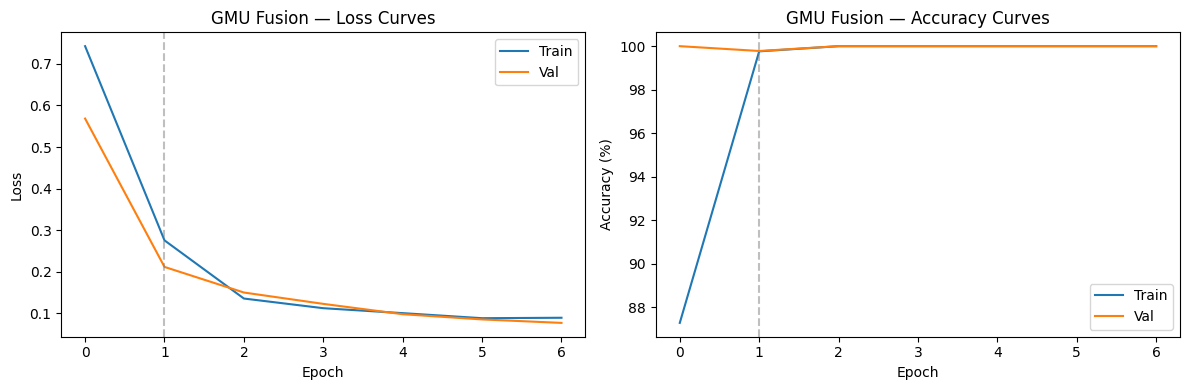

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["val_loss"], label="Val")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("GMU Fusion — Loss Curves")
ax1.legend()
ax1.axvline(x=FREEZE_EPOCHS-1, color="gray", linestyle="--", alpha=0.5)

ax2.plot([a*100 for a in history["train_acc"]], label="Train")
ax2.plot([a*100 for a in history["val_acc"]], label="Val")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("GMU Fusion — Accuracy Curves")
ax2.legend()
ax2.axvline(x=FREEZE_EPOCHS-1, color="gray", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fusion_training_curves.png"), bbox_inches="tight")
plt.show()

## 6. Test Set Evaluation

GMU Fusion Test Accuracy: 99.78% | Macro F1: 0.9978

Classification Report:
                precision    recall  f1-score   support

         Fresh       0.99      1.00      1.00       150
Formalin-Mixed       1.00      0.99      1.00       150
        Rotten       1.00      1.00      1.00       150

      accuracy                           1.00       450
     macro avg       1.00      1.00      1.00       450
  weighted avg       1.00      1.00      1.00       450



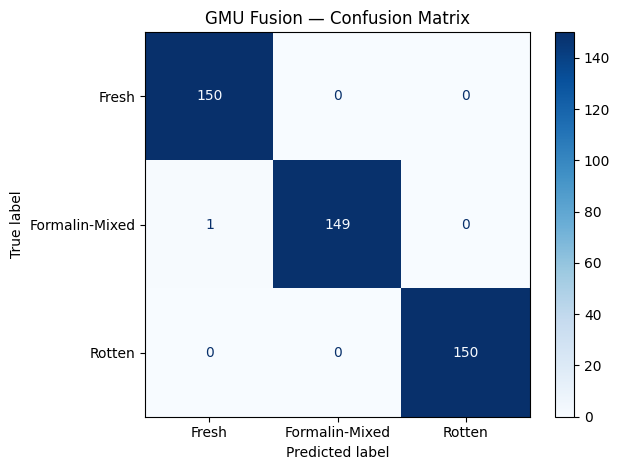

In [7]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, sensors, labels in test_loader:
        all_preds.extend(model(imgs, sensors).argmax(1).numpy())
        all_labels.extend(labels.numpy())

gmu_acc = accuracy_score(all_labels, all_preds)
gmu_f1 = f1_score(all_labels, all_preds, average='macro')
print(f"GMU Fusion Test Accuracy: {gmu_acc*100:.2f}% | Macro F1: {gmu_f1:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=TARGET_NAMES))

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=TARGET_NAMES)
disp.plot(cmap="Blues")
plt.title("GMU Fusion — Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fusion_confusion_matrix.png"), bbox_inches="tight")
plt.show()

## 7. Save Checkpoint

In [8]:
torch.save(model.state_dict(), os.path.join(MODELS_DIR, "multimodal_gmu.pth"))
print(f"Saved model to {MODELS_DIR}/multimodal_gmu.pth")
print(f"Saved scaler to {MODELS_DIR}/sensor_scaler.pkl")
print("\nThese two files are what your Streamlit app will load.")

Saved model to ../models/multimodal_gmu.pth
Saved scaler to ../models/sensor_scaler.pkl

These two files are what your Streamlit app will load.
